# R met eurostat
We gaan data inlezen van de eurostat-site: https://ec.europa.eu/eurostat<br>
<p>
LinkedIn: https://www.linkedin.com/company/eurostat/posts/?feedView=all<br>
<p>
We installeren eerst de benodigde packages en lezen de libraries in:

In [ ]:
install.packages("tidyverse")
install.packages("eurostat")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘proxy’, ‘e1071’, ‘plyr’, ‘bibtex’, ‘assertthat’, ‘here’, ‘classInt’, ‘countrycode’, ‘ISOweek’, ‘RefManageR’, ‘regions’




In [ ]:
library(tidyverse)
library(eurostat)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


Vervolgens maken we een 'query' die alle tabellen geeft met daarin het woord "accidents".

In [ ]:
query <- search_eurostat("accidents",type = "table")
query[1:3,1:2]

title,code
<chr>,<chr>
"Death due to transport accidents, by sex",tps00165
"Death due to accidents, by sex",tps00125
Death due to transport accidents by NUTS 2 region,tgs00061


We kiezen 1 tabel (Death due to transport accidents by NUTS 2 regions) en lezen de informatie in:

In [ ]:
data <- get_eurostat(id="tgs00061", time_format="num")
head(data)

Table tgs00061 cached at /tmp/RtmpDJOiNB/eurostat/bf16cc31f22f4b52b2bc9ffe07c20a21.rds



freq,unit,sex,age,icd10,geo,TIME_PERIOD,values
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>
A,RT,T,TOTAL,V_Y85,AT11,2013,7.49
A,RT,T,TOTAL,V_Y85,AT11,2014,5.95
A,RT,T,TOTAL,V_Y85,AT11,2015,5.67
A,RT,T,TOTAL,V_Y85,AT11,2016,6.02
A,RT,T,TOTAL,V_Y85,AT11,2017,5.57
A,RT,T,TOTAL,V_Y85,AT11,2018,4.14


Wel handig als we weten wat de afkortingen in de kolommen betekenen:

In [ ]:
data <- label_eurostat(data)
head(data)

freq,unit,sex,age,icd10,geo,TIME_PERIOD,values
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Burgenland,2013,7.49
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Burgenland,2014,5.95
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Burgenland,2015,5.67
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Burgenland,2016,6.02
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Burgenland,2017,5.57
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Burgenland,2018,4.14


Eens kijken of we hier ook een fijn grafiekje van kunnen maken:

Warning message:
“The shape palette can deal with a maximum of 6 discrete values because more
than 6 becomes difficult to discriminate
ℹ you have requested 333 values. Consider specifying shapes manually if you
  need that many of them.”
Warning message:
“Removed 2924 rows containing missing values or values outside the scale range
(`geom_point()`).”


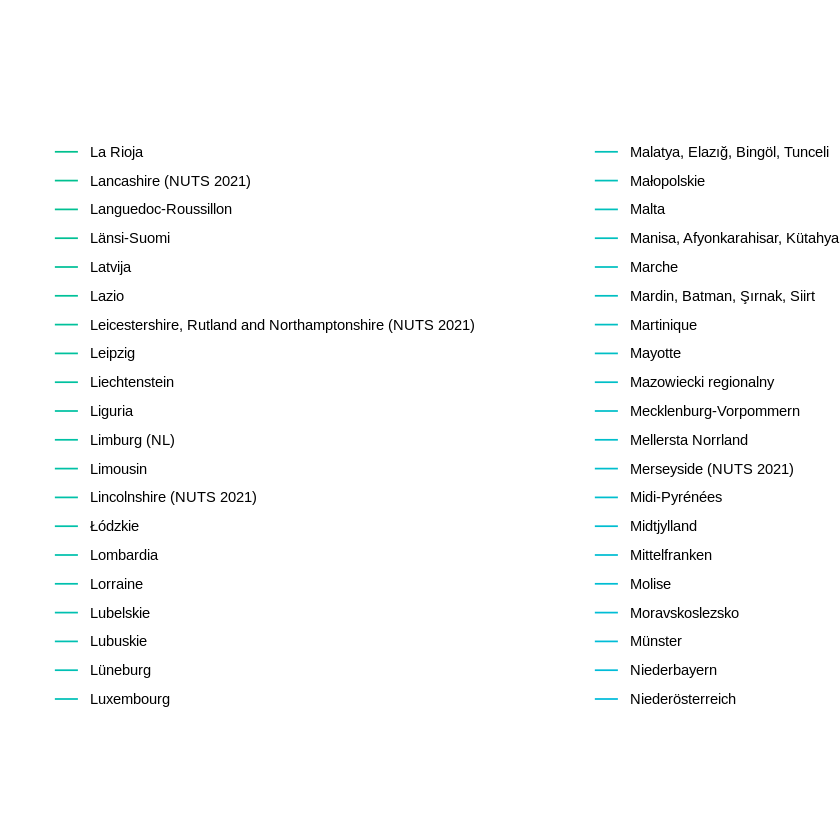

In [ ]:
ggplot(data, aes(x=TIME_PERIOD, y=values, color=geo, group=geo, shape=geo))+
  geom_point(size=2)+
  geom_line() + theme_bw()+
  labs(title="Transport accidents", x="Year", y="Victims")

Ai: we hebben 327 verschillende geo's (= landen of provincies of streken), we moeten de selectie wat beperken:

In [ ]:
data

freq,unit,sex,age,icd10,geo,TIME_PERIOD,values
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Burgenland,2013,7.49
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Burgenland,2014,5.95
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Burgenland,2015,5.67
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Burgenland,2016,6.02
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Burgenland,2017,5.57
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Burgenland,2018,4.14
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Burgenland,2019,4.90
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Burgenland,2020,4.85
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Burgenland,2021,4.45


We kunnen bijvoorbeeld filteren op jaar:

In [ ]:
new_data <- filter(data, TIME_PERIOD == 2017)
new_data

freq,unit,sex,age,icd10,geo,TIME_PERIOD,values
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Burgenland,2017,5.57
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Niederösterreich,2017,6.40
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Wien,2017,2.53
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Kärnten,2017,5.72
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Steiermark,2017,6.39
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Oberösterreich,2017,5.44
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Salzburg,2017,6.63
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Tirol,2017,4.79
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Vorarlberg,2017,3.25


Of filteren op een bepaald(e) land / provincie / streek:

In [ ]:
new_data <- filter(data, geo %in% c("Salzburg","Tirol"))
new_data

freq,unit,sex,age,icd10,geo,TIME_PERIOD,values
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Salzburg,2013,8.49
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Salzburg,2014,7.58
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Salzburg,2015,6.21
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Salzburg,2016,6.08
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Salzburg,2017,6.63
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Salzburg,2018,5.95
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Salzburg,2019,5.72
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Salzburg,2020,4.89
Annual,Rate,Total,Total,"Transport accidents (V01-V99, Y85)",Salzburg,2021,4.79


Van deze laatste selectie maken we nu opnieuw een grafiek:

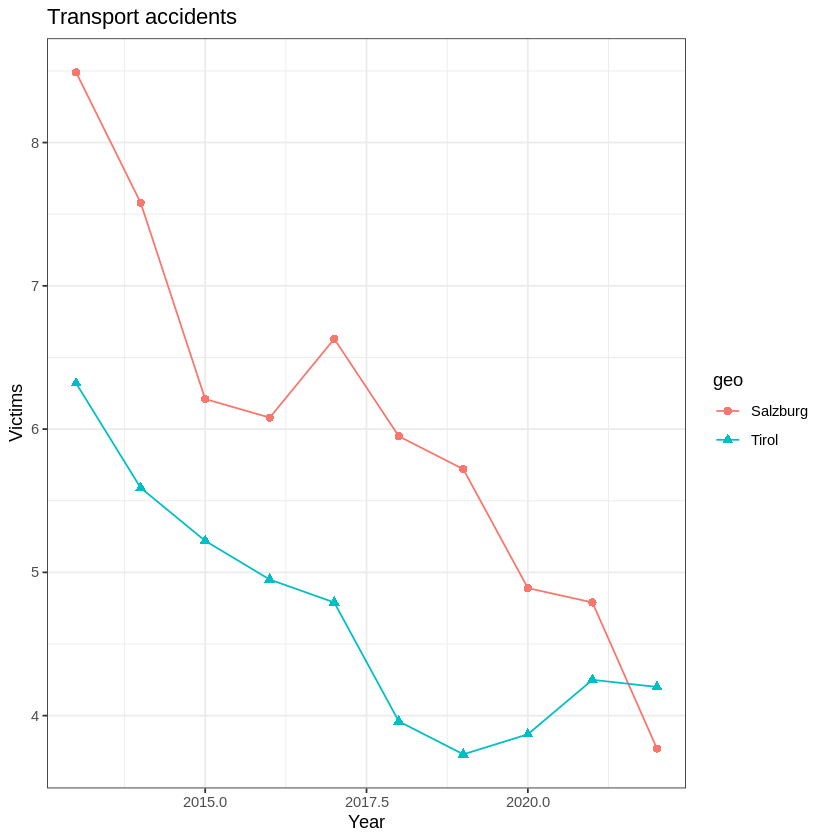

In [ ]:
ggplot(new_data, aes(x=TIME_PERIOD, y=values, color=geo, shape=geo, group=geo))+
  geom_point(size=2)+
  geom_line() + theme_bw()+
  labs(title="Transport accidents", x="Year", y="Victims")

De lijst met geo-afkortingen kun je [hier](https://ec.europa.eu/eurostat/documents/3859598/15193590/KS-GQ-22-010-EN-N.pdf/82e738dc-fe63-6594-8b2c-1b131ab3f877?t=1666687530717) downloaden.<br>
BE10 = Région de Bruxelles-Capitale/Brussels Hoofdstedelijk Gewest<br>
BE35 = Prov. Namur

Nog een mooi grafiekje:

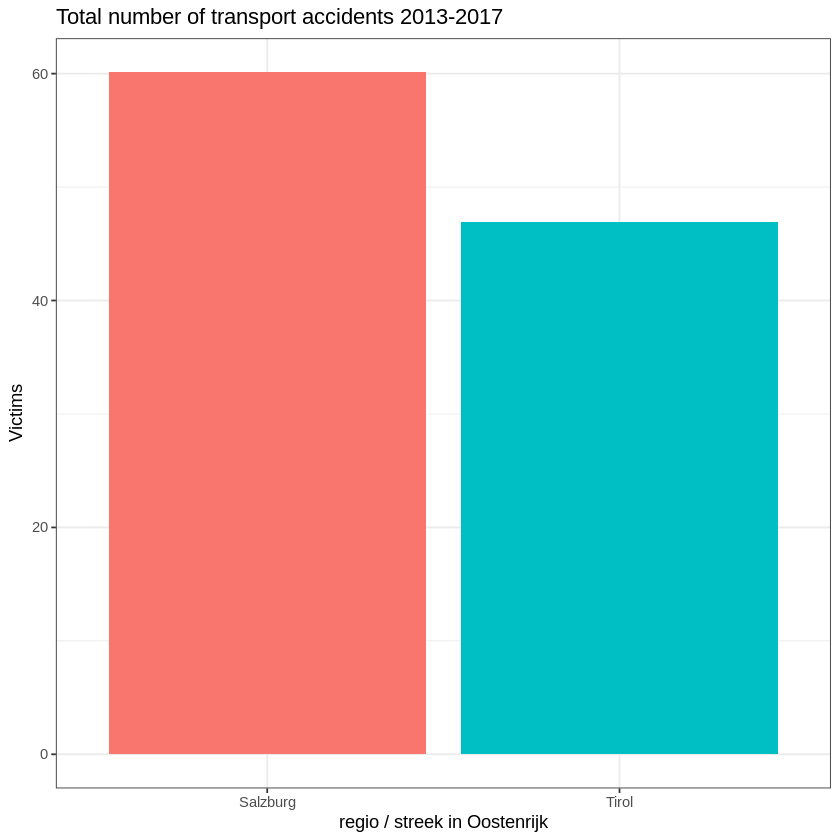

In [ ]:
ggplot(new_data, aes(geo, values, fill=geo))+
  geom_bar(stat="identity")+ theme_bw()+
  theme(legend.position = "none")+
  labs(title="Total number of transport accidents 2013-2017", x="regio / streek in Oostenrijk", y="Victims")

# Intermezzo: nuttige tabellen
Zijn er tabellen die jullie kunnen gebruiken voor de portfolio-opdracht?<br>
Ik denk het wel, bijv hier (op maandbasis) het rendement op een 10-jarige staatslening voor de VS, Japan en Turkije (vanaf 1973!):

In [ ]:
data <- get_eurostat(id="irt_lt_gby10_m", time_format="date")
data

Table irt_lt_gby10_m cached at /tmp/RtmpDJOiNB/eurostat/83b902ad748f79b9ae01285a606e09f0.rds



freq,maturity,geo,TIME_PERIOD,values
<chr>,<chr>,<chr>,<date>,<dbl>
M,Y10,JP,1973-01-01,6.43
M,Y10,JP,1973-02-01,6.58
M,Y10,JP,1973-03-01,6.64
M,Y10,JP,1973-04-01,7.04
M,Y10,JP,1973-05-01,7.08
M,Y10,JP,1973-06-01,7.09
M,Y10,JP,1973-07-01,7.24
M,Y10,JP,1973-08-01,7.43
M,Y10,JP,1973-09-01,7.52


Voor een toelichting op deze tabel: https://ec.europa.eu/eurostat/cache/metadata/en/irt_lt_gby10_esms.htm

Grafiek van deze tabel:

`geom_smooth()` using method = 'loess' and formula = 'y ~ x'


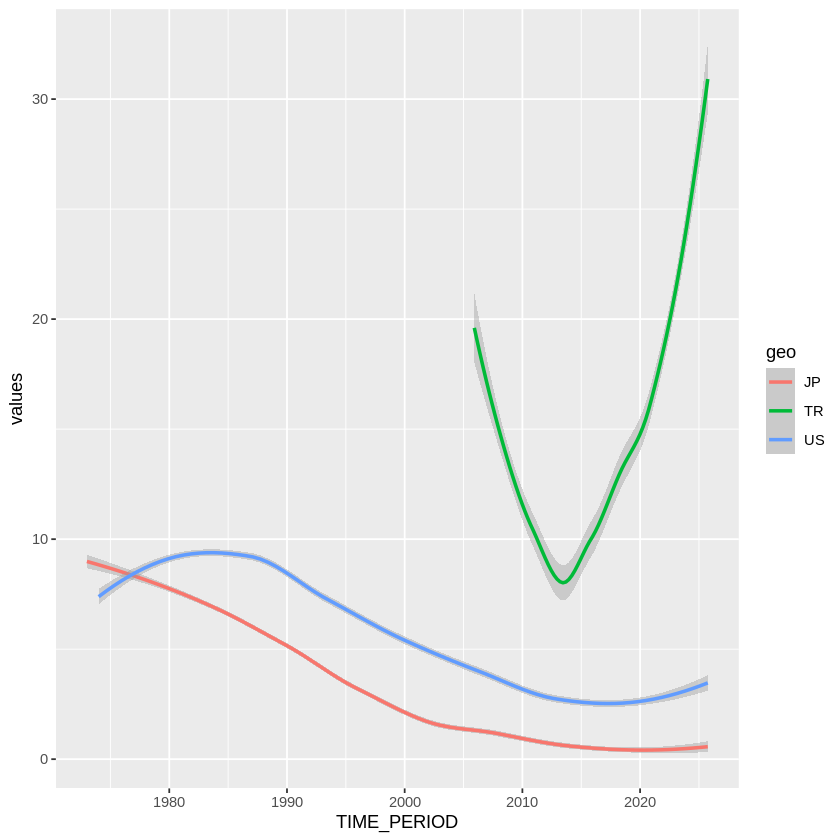

In [ ]:
ggplot(data = data, mapping = aes(x =TIME_PERIOD , y = values)) +
  geom_smooth(mapping = aes(color = geo))

Voor een overzicht van de rijkdom aan tabellen:<br>
https://ec.europa.eu/eurostat/web/main/data/database

# Eurostat and maps
We kunnen naast grafieken ook mooie kaarten met informatie maken met behulp van de data.<br>
<p>
Daarvoor installeren we eerst het sf-pakket (https://cran.r-project.org/web/packages/sf/index.html) en lezen we daarna de data in. In dit voorbeeld gebruiken we data over de 'fertility rate'.

In [ ]:
install.packages("sf")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘wk’, ‘s2’, ‘units’




In [ ]:
library(sf)

Linking to GEOS 3.12.1, GDAL 3.8.4, PROJ 9.3.1; sf_use_s2() is TRUE



In [ ]:
query <- search_eurostat(pattern="fertility rate",type = "table", fixed=FALSE)
query[,1:2]

title,code
<chr>,<chr>
Total fertility rate by NUTS 2 region,tgs00100
Total fertility rate,tps00199
Total fertility rate by NUTS 2 region,tgs00100


We willen de informatie voor alle landen in Europa, dus maken we eerst een lijst met country codes die we gaan gebruiken:

In [ ]:
landcode <- c("AT","BE","BG","CH","CY","CZ","DE","DK","EE","EL","ES",
              "FI","FR","HR","HU","IE","IS","IT","LI","LT","LU","LV",
              "MT","NL","NO","PL","PT","RO","SE","SI","SK","UK")

Nu kunnen we de data inlezen:

In [ ]:
fertility <-get_eurostat(id="tps00199", time_format="num",
  filters =list(geo = landcode))

Table tps00199 cached at /tmp/RtmpDJOiNB/eurostat/b9db9a19832cd5fd457e079fb0a87182.rds



In [ ]:
fertility <-label_eurostat(fertility)
head(fertility)

freq,indic_de,geo,time,values
<chr>,<chr>,<chr>,<dbl>,<dbl>
Annual,Total fertility rate,Belgium,2012,1.80
Annual,Total fertility rate,Belgium,2013,1.76
Annual,Total fertility rate,Belgium,2014,1.74
Annual,Total fertility rate,Belgium,2015,1.70
Annual,Total fertility rate,Belgium,2016,1.68
Annual,Total fertility rate,Belgium,2017,1.65


Even een grafiek van deze tabel:

Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_text()`).”


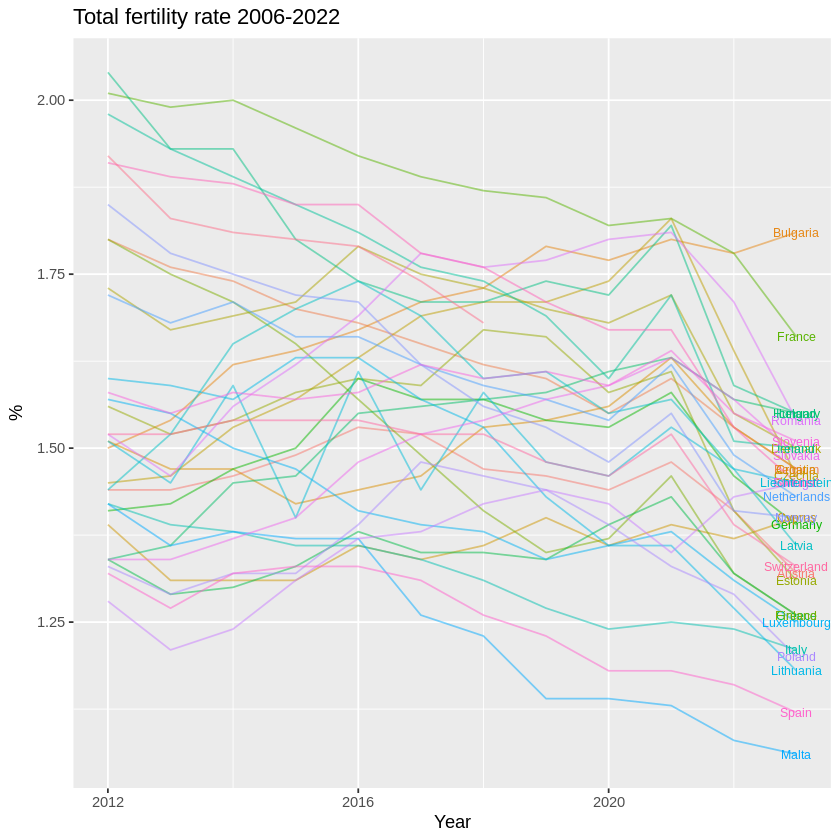

In [ ]:
ggplot(fertility, aes(x=time, y=values, color=geo, label=geo)) +
  geom_line(alpha=.5) +
  geom_text(data=fertility %>% group_by (geo) %>% filter(time == max(time)),size=2.6) +
  labs(title = "Total fertility rate 2006-2022", x="Year", y="%") +
  theme(legend.position = "none")

We gaan een aparte grafiek maken voor 2022:

In [ ]:
fertility_2022 <- fertility %>%
  filter(time == "2022")
volgorde <- arrange(fertility_2022,desc(values))
volgorde

freq,indic_de,geo,time,values
<chr>,<chr>,<chr>,<dbl>,<dbl>
Annual,Total fertility rate,Bulgaria,2022,1.78
Annual,Total fertility rate,France,2022,1.78
Annual,Total fertility rate,Romania,2022,1.71
Annual,Total fertility rate,Czechia,2022,1.64
Annual,Total fertility rate,Iceland,2022,1.59
Annual,Total fertility rate,Hungary,2022,1.57
Annual,Total fertility rate,Slovakia,2022,1.57
Annual,Total fertility rate,Denmark,2022,1.55
Annual,Total fertility rate,Slovenia,2022,1.55


We zien dat bij UK er geen waarde staat: NA.<br>
Die moeten we, voordat we de kaart gaan maken, eerst verwijderen:

In [ ]:
fertility_2022 <- drop_na(fertility_2022)

We kunnen nu een staafdiagram maken op volgorde van het gemiddelde aantal geboortes:

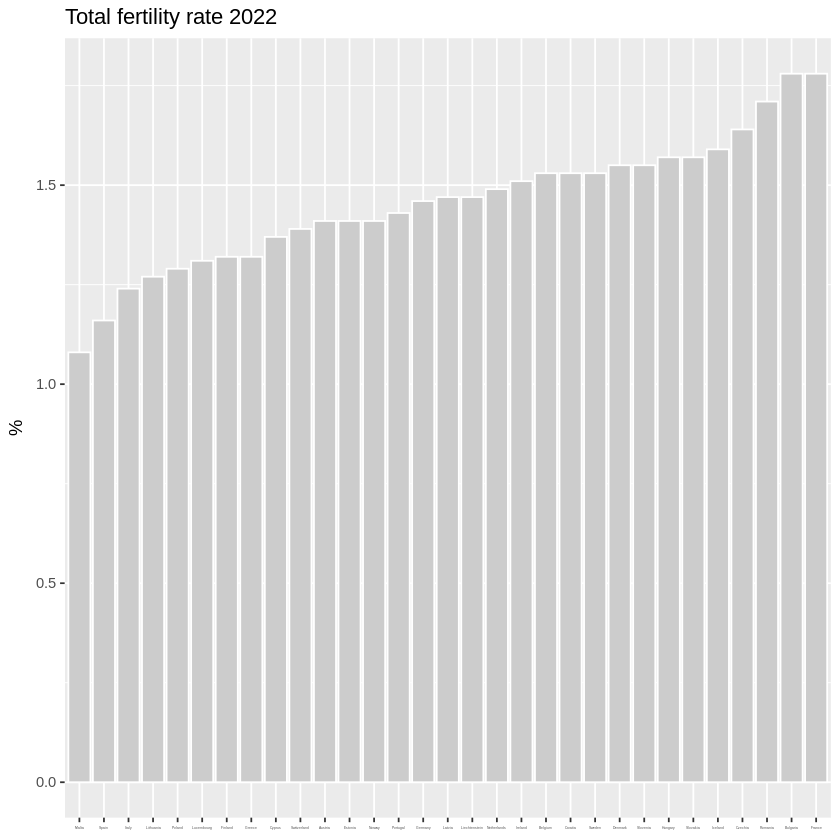

In [ ]:
ggplot(fertility_2022, aes(x=reorder(geo, values), y=values)) +
  geom_col(color="white", fill="grey80") +
  labs(title = "Total fertility rate 2022", y="%", x=NULL) +
  theme(axis.text.x = element_text(size=2))

## De Map (deel 1)
We maken een kaart-variabele aan waaraan we de vruchtbaarheidsinformatie toevoegen:

In [ ]:
mapdata <- get_eurostat_geospatial(nuts_level=0) %>%
  right_join(y=fertility_2022) %>%
  mutate(cat = cut_to_classes(values,n=4,decimals=1))

Extracting data from eurostat::eurostat_geodata_60_2016

Joining with `by = join_by(geo)`


Even kijken hoe de 'map'-data er nu uitziet:

In [ ]:
head(select(mapdata,geo,values,cat),3)

ERROR while rich displaying an object: Error in loadNamespace(x): there is no package called ‘geojsonio’

Traceback:
1. sapply(x, f, simplify = simplify)
2. lapply(X = X, FUN = FUN, ...)
3. FUN(X[[i]], ...)
4. tryCatch(withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = error_handler), error = outer_handler)
5. tryCatchList(expr, classes, parentenv, handlers)
6. tryCatchOne(expr, names, parentenv, handlers[[1L]])
7. doTryCatch(return(expr), name, parentenv, handler)
8. withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = 

,geo,values,cat,geometry
,<chr>,<dbl>,<fct>,<GEOMETRYCOLLECTION [°]>
1,Belgium,1.53,1.4 ~< 1.6,GEOMETRYCOLLECTION EMPTY
2,Bulgaria,1.78,1.6 ~< 1.8,GEOMETRYCOLLECTION EMPTY
3,Czechia,1.64,1.6 ~< 1.8,GEOMETRYCOLLECTION EMPTY


Nu maken we er een mooie totaalgrafiek van:

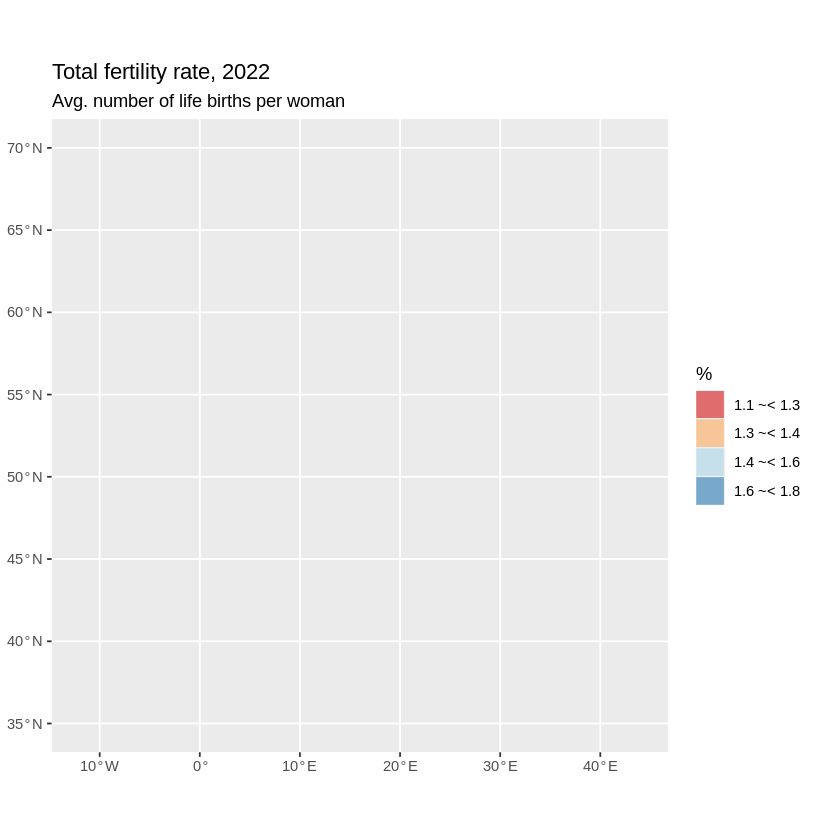

In [ ]:
ggplot(mapdata, aes(fill=cat)) +
  scale_fill_brewer(palette="RdYlBu")+
  geom_sf(color=alpha("white",1/3), alpha=.6) +
  xlim(c(-12,44)) + ylim(c(35,70)) +
  labs(title = "Total fertility rate, 2022", subtitle = "Avg. number of life births per woman", fill="%")

Dit werkt niet in deze Google Colab, maar als je bovenstaande code in R zelf draait .. doet ie het (niet)?!

<p>

Wie heeft dit allemaal bedacht: de developers: https://ropengov.github.io/eurostat/

En er is natuurlijk een cheat-sheet: https://github.com/rstudio/cheatsheets/blob/main/eurostat.pdf

## De Map (deel 2)
Onderstaande code laat de kaart van Europa zien:

Extracting data from eurostat::eurostat_geodata_60_2016



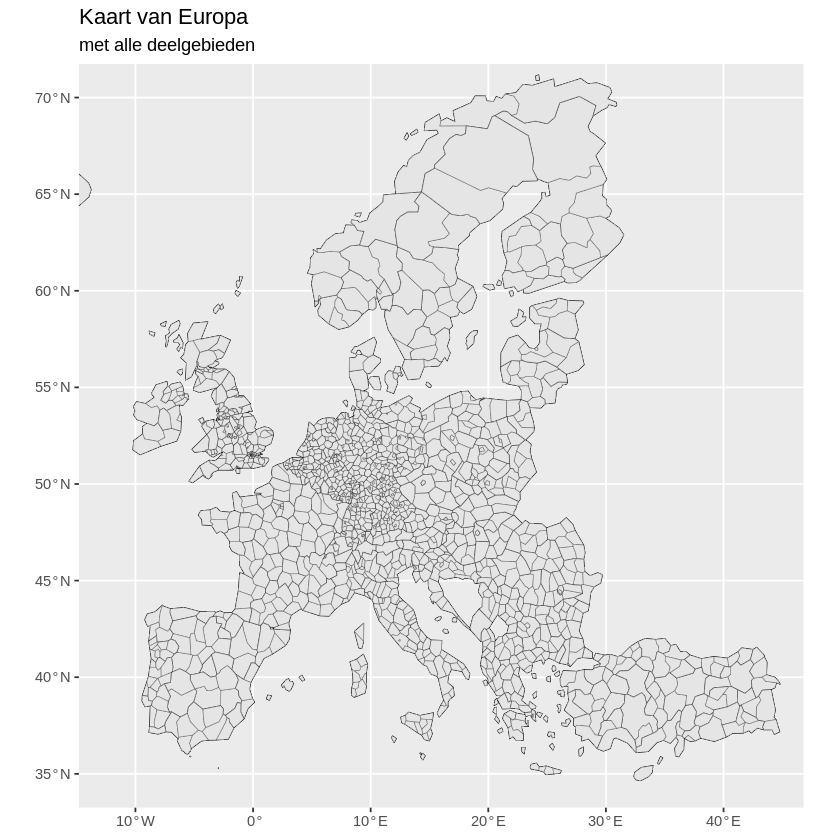

In [ ]:
map <- get_eurostat_geospatial(output_class = "sf", resolution = "60")
ggplot(map) +
    geom_sf(color=alpha("black",1/3), alpha=.6) +
    xlim(c(-12,44)) + ylim(c(35,70)) +
    labs(title = "Kaart van Europa", subtitle = "met alle deelgebieden")

En deze code laat verschillende varianten van de kaart van Europa zien:

Extracting data from eurostat::eurostat_geodata_60_2016

Warning message:
“plotting the first 9 out of 11 attributes; use max.plot = 11 to plot all”


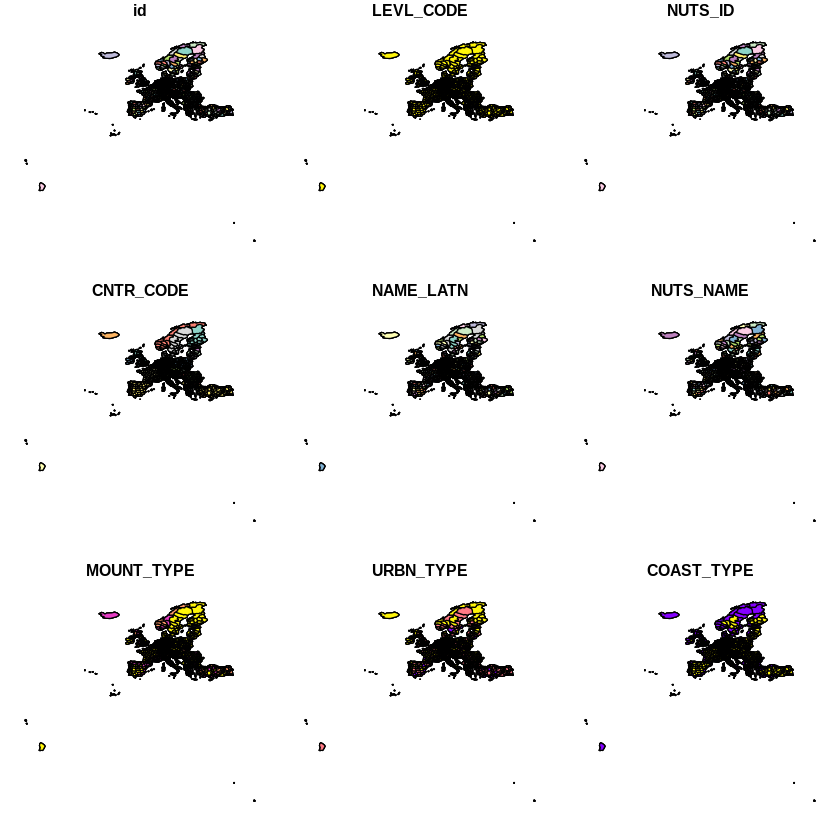

In [ ]:
map <- get_eurostat_geospatial(output_class = "sf", resolution = "60")
plot(map)

Als je alle namen van alle deelgebieden wilt zien:

Warning message in st_point_on_surface.sfc(sf::st_zm(x)):
“st_point_on_surface may not give correct results for longitude/latitude data”
Warning message:
“Removed 36 rows containing missing values or values outside the scale range
(`geom_text()`).”


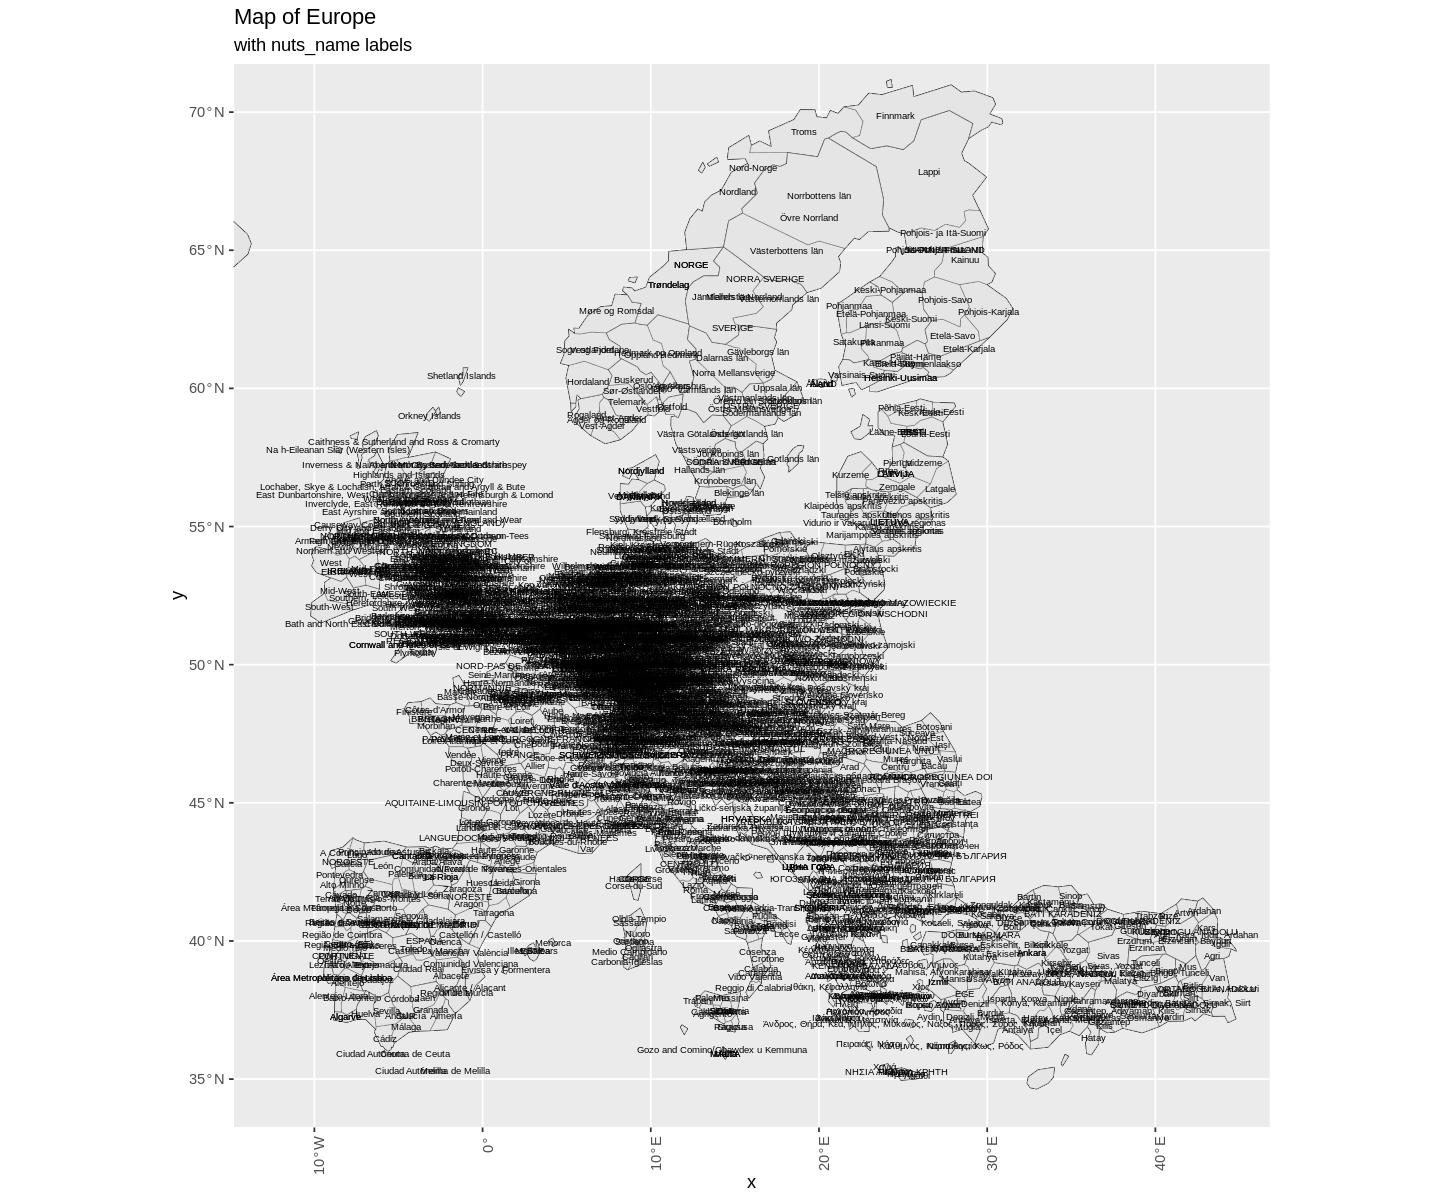

In [ ]:
options(repr.plot.width = 12, repr.plot.height = 10)
ggplot(map) +
  geom_sf(color=alpha("black",1/3), alpha=.6) +
  geom_sf_text(aes(label = NUTS_NAME), size = 2) +  # Add labels with NUTS_NAME
  xlim(c(-12,44)) + ylim(c(35,70)) +
  labs(title = "Map of Europe", subtitle = "with nuts_name labels") +
  theme(axis.text.x = element_text(angle = 90, hjust = 1))  # Rotate x-axis labels for readability

Lekker leesbaar? Dacht het niet ...

## Kaart van Nederland

Warning message in st_point_on_surface.sfc(sf::st_zm(x)):
“st_point_on_surface may not give correct results for longitude/latitude data”


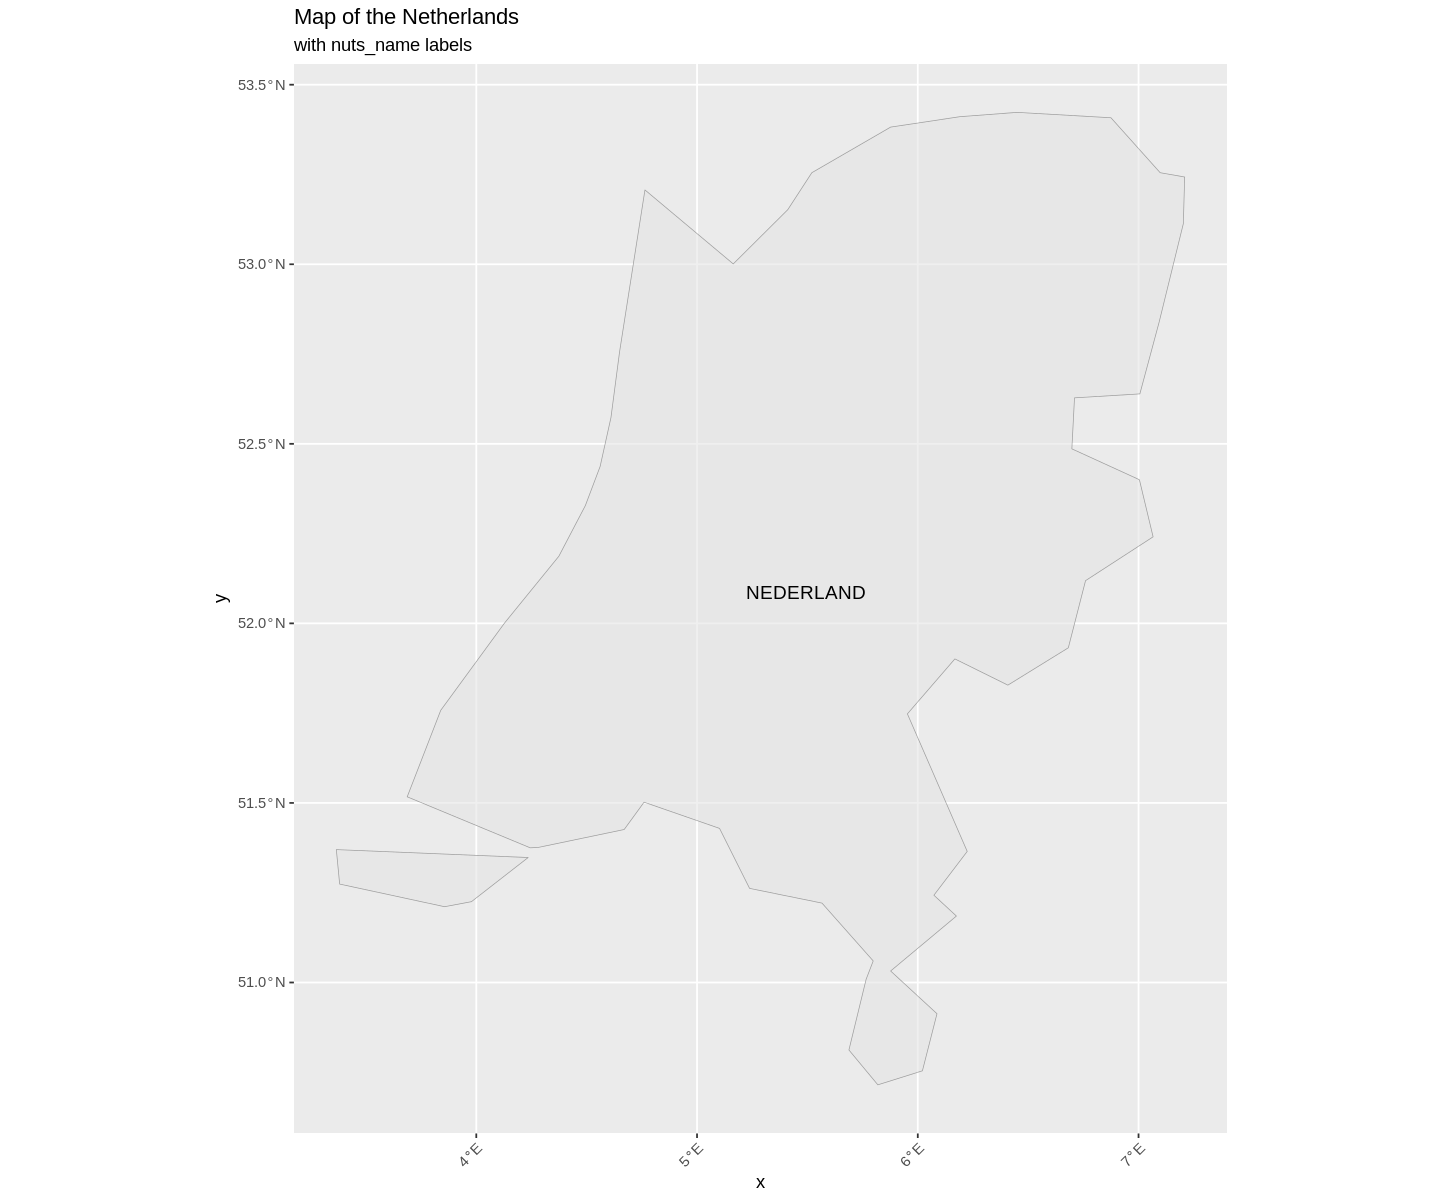

In [ ]:
options(repr.plot.width = 12, repr.plot.height = 10)
nl_map <- filter(map, geo == "NL")

ggplot(nl_map) +
  geom_sf(color=alpha("black",1/3), alpha=.6) +
  geom_sf_text(aes(label = NUTS_NAME), size = 4) + # Increased text size for better readability
  labs(title = "Map of the Netherlands", subtitle = "with nuts_name labels") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1)) # Adjusted x-axis label angle

## Kaart van Belgie

Warning message in st_point_on_surface.sfc(sf::st_zm(x)):
“st_point_on_surface may not give correct results for longitude/latitude data”


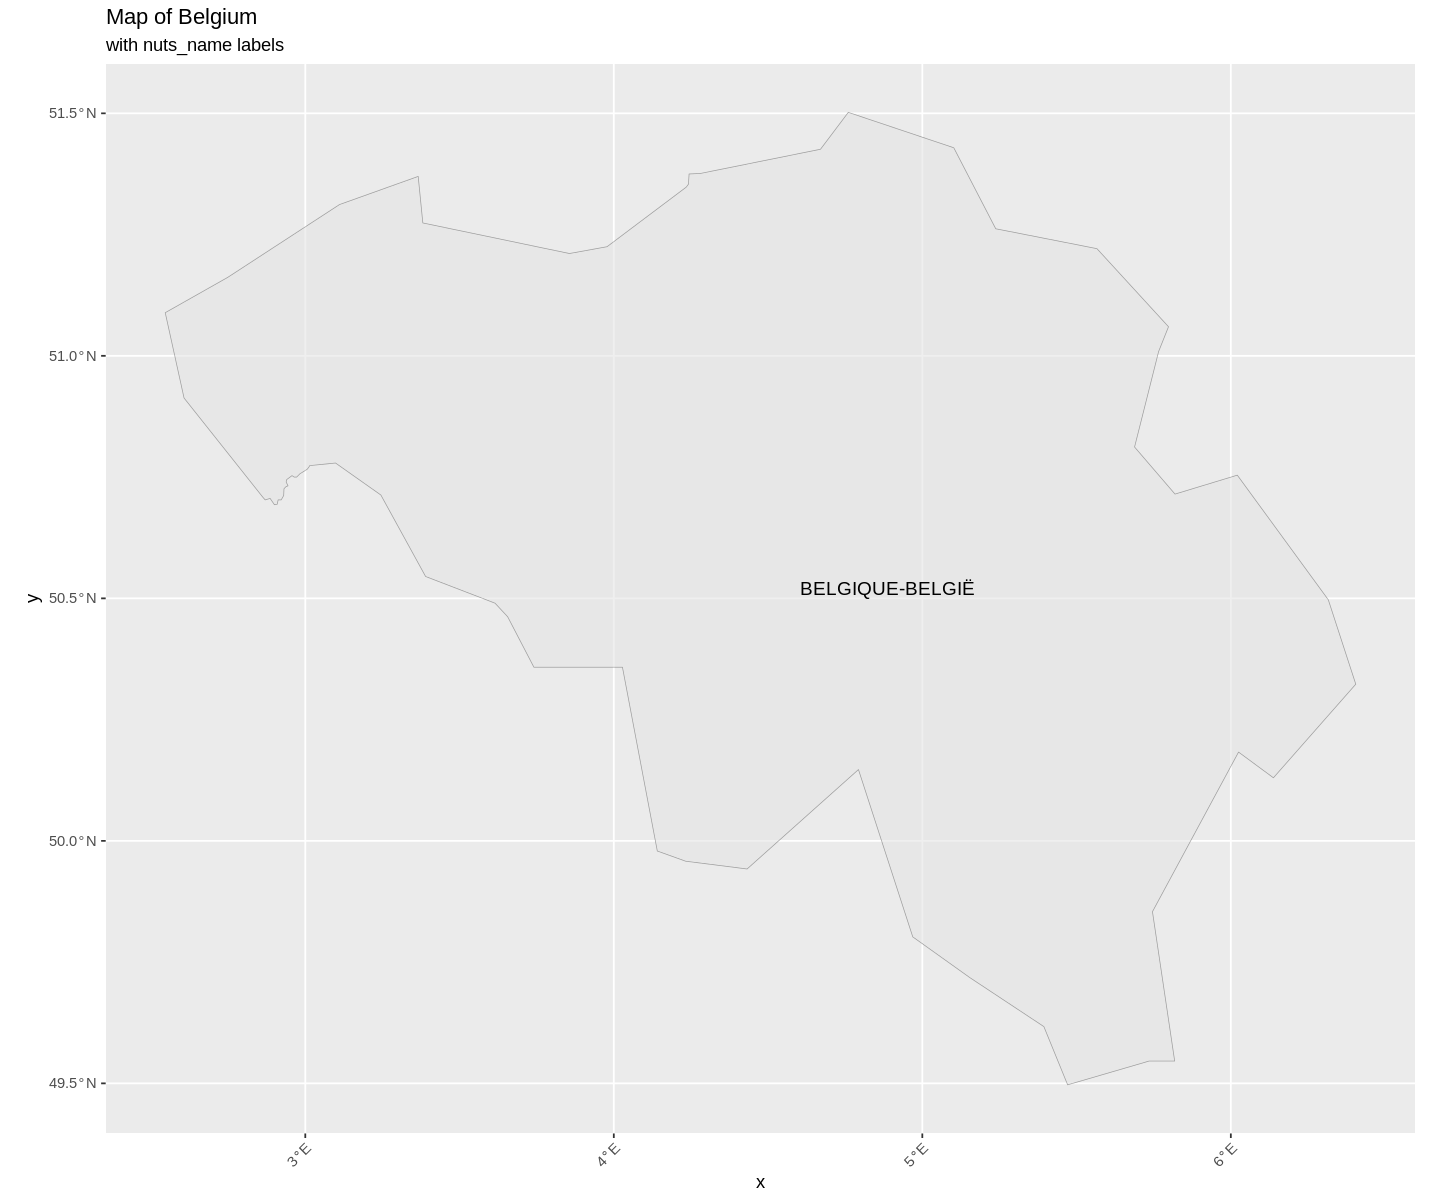

In [ ]:
options(repr.plot.width = 12, repr.plot.height = 10)
nl_map <- filter(map, geo == "BE")

ggplot(nl_map) +
  geom_sf(color=alpha("black",1/3), alpha=.6) +
  geom_sf_text(aes(label = NUTS_NAME), size = 4) + # Increased text size for better readability
  labs(title = "Map of Belgium", subtitle = "with nuts_name labels") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1)) # Adjusted x-axis label angle